# 1. Project Overview

This project investigates the adversarial robustness of machine-learning-based network intrusion detection systems using UNSW-NB15. It compares baseline classifiers and evaluates constrained gradient-based feature perturbations against a random-perturbation control.

In [ ]:
# Project: Constraint-Aware Adversarial Robustness
# Dataset: UNSW-NB15
# Dataset audit and clean baseline

import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

warnings.filterwarnings("default")

print("Environment initialized")
print("Random seed:", SEED)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Environment initialized
Random seed: 42
NumPy: 2.1.3
Pandas: 2.2.3


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# 2. Dataset Loading and Audit

Load the supplied training and official testing files. Inspect their dimensions, class distributions, feature types, and attack categories before model development.

In [ ]:
import pandas as pd
from pathlib import Path

# Locate the files in Colab's Files panel
DATA_DIR = Path("/content")

train_path = DATA_DIR / "UNSW_NB15_training-set.csv"
test_path = DATA_DIR / "UNSW_NB15_testing-set.csv"

# Load datasets
train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nFirst five training records:")
display(train_df.head())

Training shape: (175341, 45)
Testing shape: (82332, 45)

Training columns:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']

First five training records:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


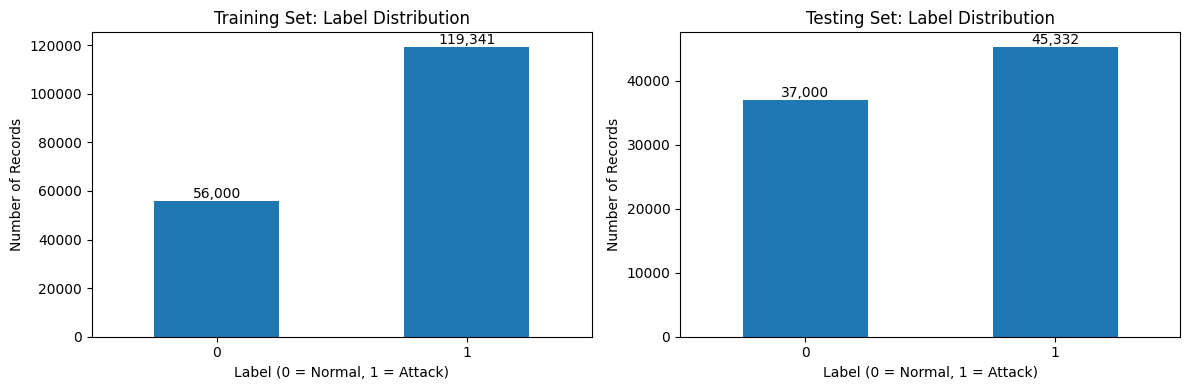

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, df) in zip(
    axes,
    [("Training", train_df), ("Testing", test_df)]
):
    counts = df["label"].value_counts().sort_index()

    counts.plot(kind="bar", ax=ax)
    ax.set_title(f"{name} Set: Label Distribution")
    ax.set_xlabel("Label (0 = Normal, 1 = Attack)")
    ax.set_ylabel("Number of Records")
    ax.tick_params(axis="x", rotation=0)

    for i, count in enumerate(counts):
        ax.text(i, count, f"{count:,}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

In [ ]:
# Cell 5: Feature type and leakage audit

print("Column names and data types:\n")
display(
    pd.DataFrame({
        "column": train_df.columns,
        "dtype": train_df.dtypes.astype(str).values,
        "unique_values": [
            train_df[col].nunique(dropna=False)
            for col in train_df.columns
        ]
    })
)

print("\nTarget-related columns:")
print([
    col for col in train_df.columns
    if col.lower() in {"label", "attack_cat", "id"}
])

print("\nCategorical feature candidates:")
print(
    train_df.select_dtypes(include=["object", "category"])
    .nunique()
    .sort_values(ascending=False)
)

Column names and data types:



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,column,dtype,unique_values
0,id,int64,175341
1,dur,float64,74039
2,proto,object,133
3,service,object,13
4,state,object,9
5,spkts,int64,480
6,dpkts,int64,443
7,sbytes,int64,7214
8,dbytes,int64,6660
9,rate,float64,76991



Target-related columns:
['id', 'attack_cat', 'label']

Categorical feature candidates:
proto         133
service        13
attack_cat     10
state           9
dtype: int64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# Attack-category coverage

for name, df in [("TRAINING", train_df), ("TESTING", test_df)]:
    print(f"\n{name} attack categories:")

    if "attack_cat" in df.columns:
        print(
            df.loc[df["label"] == 1, "attack_cat"]
            .value_counts(dropna=False)
        )
    else:
        print("No attack_cat column found.")


TRAINING attack categories:
attack_cat
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

TESTING attack categories:
attack_cat
Generic           18871
Exploits          11132
Fuzzers            6062
DoS                4089
Reconnaissance     3496
Analysis            677
Backdoor            583
Shellcode           378
Worms                44
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# 3. Preprocessing and Data Split

Excluding identifiers and target-related columns from the inputs. Create a stratified training/validation split, fit preprocessing only on the training partition, and apply the fitted transformations to validation and official test data.

In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

SEED = 42

# Exclude identifiers and all target-related fields
excluded_columns = ["id", "attack_cat", "label"]

feature_columns = [
    col for col in train_df.columns
    if col not in excluded_columns
]

X = train_df[feature_columns].copy()
y = train_df["label"].astype(int).copy()

X_test = test_df[feature_columns].copy()
y_test = test_df["label"].astype(int).copy()

# Identify categorical and numeric inputs
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_features = [
    col for col in X.columns
    if col not in categorical_features
]

print("Number of input features:", len(feature_columns))
print("Numeric features:", len(numeric_features))
print("Categorical features:", categorical_features)

print("\nTraining target distribution:")
print(y.value_counts().sort_index())

print("\nOfficial test target distribution:")
print(y_test.value_counts().sort_index())

Number of input features: 42
Numeric features: 39
Categorical features: ['proto', 'service', 'state']

Training target distribution:
label
0     56000
1    119341
Name: count, dtype: int64

Official test target distribution:
label
0    37000
1    45332
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

# Fit only on the training portion
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation and test data without refitting
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_val_processed.shape)
print("Processed test shape:", X_test_processed.shape)

Processed training shape: (140272, 192)
Processed validation shape: (35069, 192)
Processed test shape: (82332, 192)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# 4. Baseline Classifiers

Training Logistic Regression, Random Forest, and a scikit-learn MLP. Compare their validation performance using attack precision, attack recall, macro-F1, false-negative rate, and training time.

In [ ]:
import time

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=SEED
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1
    ),

    "MLP": MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        solver="adam",
        alpha=0.0001,
        batch_size=512,
        learning_rate_init=0.001,
        max_iter=40,
        early_stopping=True,
        validation_fraction=0.1,
        random_state=SEED
    )
}

trained_models = {}
training_times = {}

for name, model in models.items():
    print(f"\nTraining {name}...")
    start = time.time()

    model.fit(X_train_processed, y_train)

    elapsed = time.time() - start
    trained_models[name] = model
    training_times[name] = elapsed

    print(f"Completed in {elapsed:.1f} seconds")


Training Logistic Regression...


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Completed in 6.1 seconds

Training Random Forest...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Completed in 86.0 seconds

Training MLP...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Completed in 74.8 seconds


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (40) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

results = []

for name, model in trained_models.items():
    predictions = model.predict(X_val_processed)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision (Attack)": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall (Attack)": recall_score(
            y_val, predictions, zero_division=0
        ),
        "Macro-F1": f1_score(
            y_val, predictions, average="macro", zero_division=0
        ),
        "False Negative Rate": fn / (fn + tp) if (fn + tp) else 0,
        "Training Time (s)": training_times[name]
    })

results_df = pd.DataFrame(results).sort_values(
    "Macro-F1", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision (Attack),Recall (Attack),Macro-F1,False Negative Rate,Training Time (s)
0,Random Forest,0.9582,0.9703,0.9682,0.9519,0.0318,85.9558
1,MLP,0.9468,0.9482,0.9752,0.9378,0.0248,74.8303
2,Logistic Regression,0.9326,0.9503,0.9507,0.9225,0.0493,6.1324


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


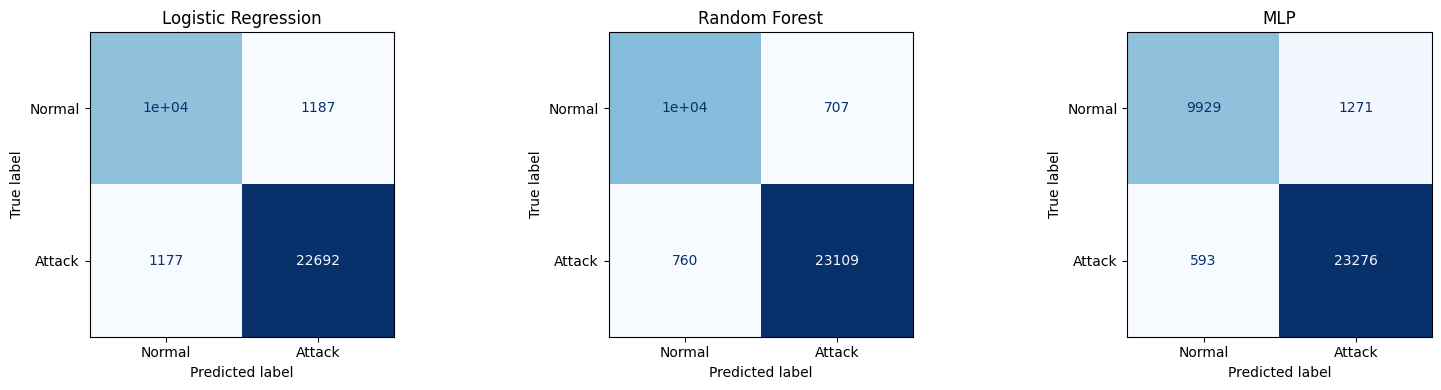

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, model) in zip(axes, trained_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_val_processed,
        y_val,
        display_labels=["Normal", "Attack"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import classification_report

for name, model in trained_models.items():
    print(f"\n{'=' * 55}")
    print(name)
    print("=" * 55)

    predictions = model.predict(X_val_processed)

    print(classification_report(
        y_val,
        predictions,
        labels=[0, 1],
        target_names=["Normal", "Attack"],
        digits=4,
        zero_division=0
    ))


Logistic Regression
              precision    recall  f1-score   support

      Normal     0.8948    0.8940    0.8944     11200
      Attack     0.9503    0.9507    0.9505     23869

    accuracy                         0.9326     35069
   macro avg     0.9226    0.9224    0.9225     35069
weighted avg     0.9326    0.9326    0.9326     35069


Random Forest


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


              precision    recall  f1-score   support

      Normal     0.9325    0.9369    0.9347     11200
      Attack     0.9703    0.9682    0.9692     23869

    accuracy                         0.9582     35069
   macro avg     0.9514    0.9525    0.9519     35069
weighted avg     0.9582    0.9582    0.9582     35069


MLP
              precision    recall  f1-score   support

      Normal     0.9436    0.8865    0.9142     11200
      Attack     0.9482    0.9752    0.9615     23869

    accuracy                         0.9468     35069
   macro avg     0.9459    0.9308    0.9378     35069
weighted avg     0.9468    0.9468    0.9464     35069



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
from pathlib import Path

RESULTS_DIR = Path("/content/results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    RESULTS_DIR / "baseline_validation_metrics.csv",
    index=False
)

print("Saved baseline validation metrics:")
print(RESULTS_DIR / "baseline_validation_metrics.csv")

Saved baseline validation metrics:
/content/results/baseline_validation_metrics.csv


# 5. PyTorch MLP

Training a separate neural-network classifier with early stopping based on validation loss. This model is used as the surrogate for generating gradient-based perturbations.

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Compute device:", device)
print("Processed training shape:", X_train_processed.shape)

PyTorch version: 2.11.0+cpu
Compute device: cpu
Processed training shape: (140272, 192)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# Convert sparse matrices to dense arrays if needed
def to_dense_float32(x):
    if hasattr(x, "toarray"):
        x = x.toarray()
    return np.asarray(x, dtype=np.float32)

Xtr = to_dense_float32(X_train_processed)
Xva = to_dense_float32(X_val_processed)

ytr = y_train.to_numpy(dtype=np.float32)
yva = y_val.to_numpy(dtype=np.float32)

Xtr_t = torch.tensor(Xtr)
ytr_t = torch.tensor(ytr).reshape(-1, 1)

Xva_t = torch.tensor(Xva)
yva_t = torch.tensor(yva).reshape(-1, 1)

train_loader = DataLoader(
    TensorDataset(Xtr_t, ytr_t),
    batch_size=512,
    shuffle=True
)

class NIDSMLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)

torch_model = NIDSMLP(Xtr.shape[1]).to(device)

print(torch_model)

NIDSMLP(
  (network): Sequential(
    (0): Linear(in_features=192, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [ ]:
from copy import deepcopy

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    torch_model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

Xva_device = Xva_t.to(device)
yva_device = yva_t.to(device)

best_val_loss = float("inf")
best_state = None
patience = 5
epochs_without_improvement = 0
MAX_EPOCHS = 40

for epoch in range(MAX_EPOCHS):
    torch_model.train()
    running_loss = 0.0

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()
        logits = torch_model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(xb)

    train_loss = running_loss / len(train_loader.dataset)

    torch_model.eval()
    with torch.no_grad():
        val_logits = torch_model(Xva_device)
        val_loss = criterion(val_logits, yva_device).item()

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train loss: {train_loss:.4f} | "
        f"Validation loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = deepcopy(torch_model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping.")
        break

torch_model.load_state_dict(best_state)
print("Best validation loss:", round(best_val_loss, 4))

Epoch 01 | Train loss: 0.2007 | Validation loss: 0.1265


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Epoch 02 | Train loss: 0.1257 | Validation loss: 0.1211
Epoch 03 | Train loss: 0.1220 | Validation loss: 0.1203
Epoch 04 | Train loss: 0.1193 | Validation loss: 0.1190
Epoch 05 | Train loss: 0.1182 | Validation loss: 0.1156
Epoch 06 | Train loss: 0.1170 | Validation loss: 0.1166
Epoch 07 | Train loss: 0.1163 | Validation loss: 0.1156
Epoch 08 | Train loss: 0.1157 | Validation loss: 0.1136
Epoch 09 | Train loss: 0.1150 | Validation loss: 0.1125
Epoch 10 | Train loss: 0.1140 | Validation loss: 0.1130
Epoch 11 | Train loss: 0.1136 | Validation loss: 0.1126
Epoch 12 | Train loss: 0.1128 | Validation loss: 0.1133
Epoch 13 | Train loss: 0.1127 | Validation loss: 0.1148
Epoch 14 | Train loss: 0.1126 | Validation loss: 0.1126
Early stopping.
Best validation loss: 0.1125


In [ ]:
from sklearn.metrics import accuracy_score, f1_score, recall_score

torch_model.eval()

with torch.no_grad():
    val_logits = torch_model(Xva_device)
    val_probs = torch.sigmoid(val_logits).cpu().numpy().ravel()

val_preds = (val_probs >= 0.5).astype(int)

print("PyTorch MLP validation results")
print("Accuracy:", round(accuracy_score(y_val, val_preds), 4))
print("Attack recall:", round(recall_score(y_val, val_preds), 4))
print(
    "Macro-F1:",
    round(f1_score(y_val, val_preds, average="macro"), 4)
)

print("\nClassification report:")
print(classification_report(
    y_val,
    val_preds,
    target_names=["Normal", "Attack"],
    digits=4,
    zero_division=0
))

PyTorch MLP validation results
Accuracy: 0.946
Attack recall: 0.9789
Macro-F1: 0.9365

Classification report:
              precision    recall  f1-score   support

      Normal     0.9511    0.8758    0.9119     11200
      Attack     0.9438    0.9789    0.9610     23869

    accuracy                         0.9460     35069
   macro avg     0.9475    0.9273    0.9365     35069
weighted avg     0.9461    0.9460    0.9453     35069



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# 6. Feature Analysis and Threat Model

Inspect numerical traffic features and their correlations. Define the seven features permitted to change during the attack. The current threat model operates in standardized feature space, so perturbations are not guaranteed to correspond to feasible network traffic.

In [ ]:
# Original numeric features, before preprocessing
numeric_summary = train_df[numeric_features].describe().T

numeric_summary["zero_fraction"] = (
    train_df[numeric_features] == 0
).mean()

numeric_summary["unique_values"] = (
    train_df[numeric_features].nunique()
)

numeric_summary = numeric_summary.sort_values(
    by="unique_values",
    ascending=False
)

display(numeric_summary.round(4))

,count,mean,std,min,25%,50%,75%,max,zero_fraction,unique_values
sload,175341.0,7.345403e+07,1.883574e+08,0.0,13053.3389,879674.7500,8.888889e+07,5.988000e+09,0.0170,80885
sjit,175341.0,4.976254e+03,4.496585e+04,0.0,0.0000,0.0000,2.513295e+03,1.460480e+06,0.5047,77532
dload,175341.0,6.712056e+05,2.421312e+06,0.0,0.0000,1447.0227,2.784487e+04,2.242273e+07,0.4807,77474
rate,175341.0,9.540619e+04,1.654010e+05,0.0,32.7861,3225.8065,1.250000e+05,1.000000e+06,0.0169,76991
djit,175341.0,6.043538e+02,4.061043e+03,0.0,0.0000,0.0000,1.149906e+02,2.893883e+05,0.5346,76831
sinpkt,175341.0,9.859769e+02,7.242246e+03,0.0,0.0080,0.2797,5.515690e+01,8.437150e+04,0.0034,76161
stcpb,175341.0,9.692504e+08,1.355264e+09,0.0,0.0000,0.0000,1.916651e+09,4.294959e+09,0.5489,75265
dtcpb,175341.0,9.688770e+08,1.354000e+09,0.0,0.0000,0.0000,1.913675e+09,4.294882e+09,0.5489,75089
dinpkt,175341.0,8.821630e+01,9.870932e+02,0.0,0.0000,0.0060,5.105300e+01,5.671682e+04,0.4807,74245
dur,175341.0,1.359400e+00,6.480200e+00,0.0,0.0000,0.0016,6.681000e-01,6.000000e+01,0.0152,74039


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


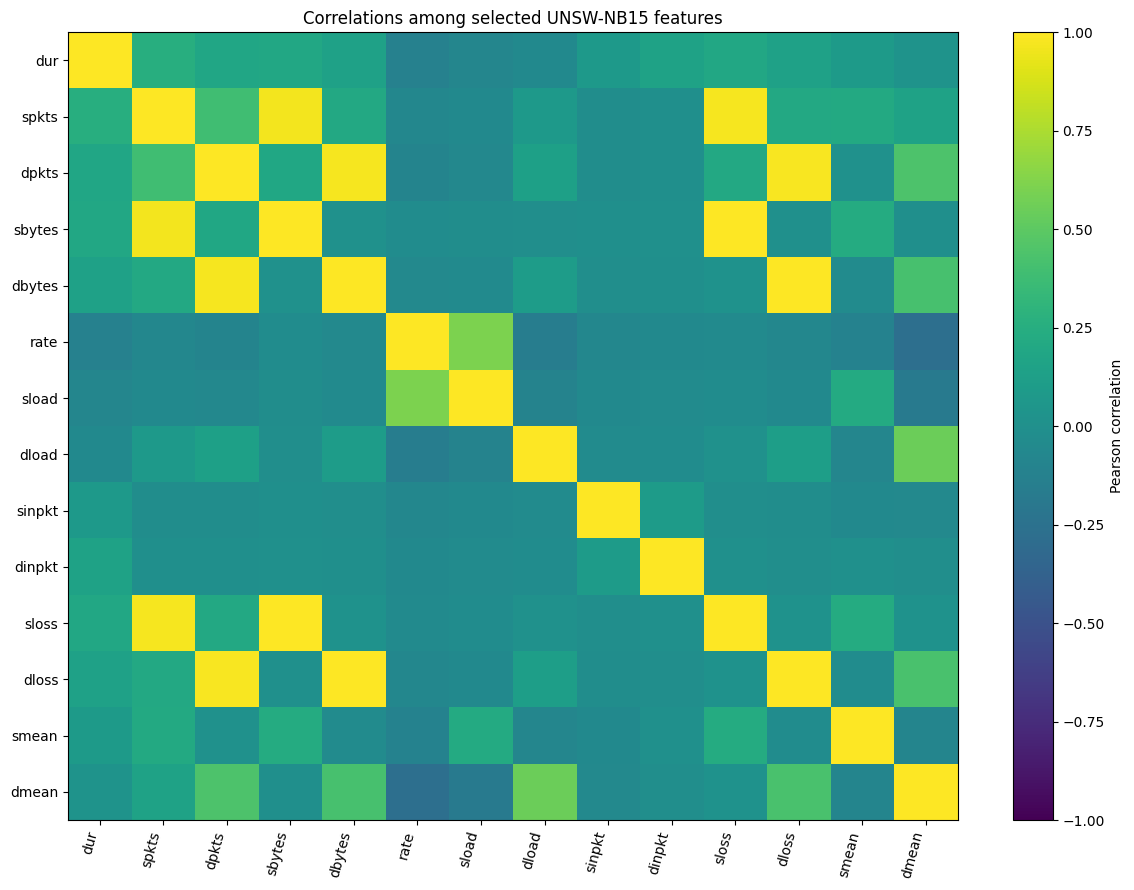

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# Correlations among selected traffic-volume and timing features

candidate_features = [
    "dur", "spkts", "dpkts", "sbytes", "dbytes",
    "rate", "sload", "dload", "sinpkt", "dinpkt",
    "sloss", "dloss", "smean", "dmean"
]

corr = train_df[candidate_features].corr()

plt.figure(figsize=(12, 9))
plt.imshow(corr, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Pearson correlation")
plt.xticks(
    range(len(candidate_features)),
    candidate_features,
    rotation=75,
    ha="right"
)
plt.yticks(range(len(candidate_features)), candidate_features)
plt.title("Correlations among selected UNSW-NB15 features")
plt.tight_layout()
plt.show()

In [ ]:
# Numerical features that the adversarial attack is allowed to modify.
# Categorical features and all other features remain unchanged.

mutable_features = [
    "dur",       # Connection duration
    "sinpkt",    # Source packet inter-arrival time
    "dinpkt",    # Destination packet inter-arrival time
    "sjit",      # Source packet jitter
    "djit",      # Destination packet jitter
    "sload",     # Source bits per second
    "dload",     # Destination bits per second
]

# Map the selected original features to their positions
# in the preprocessed feature matrix.
feature_names_processed = preprocessor.get_feature_names_out().tolist()

mutable_indices = [
    feature_names_processed.index(f"numeric__{feature}")
    for feature in mutable_features
]

print("Mutable features:", mutable_features)
print("Number of mutable features:", len(mutable_indices))
print("Processed feature indices:", mutable_indices)

# Confirm that every selected feature is numerical and exists
assert all(feature in numeric_features for feature in mutable_features)
assert len(mutable_indices) == len(mutable_features)
assert len(set(mutable_indices)) == len(mutable_indices)

print("Feature checks passed.")

Mutable features: ['dur', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'sload', 'dload']
Number of mutable features: 7
Processed feature indices: [0, 12, 13, 14, 15, 8, 9]
Feature checks passed.


# 7. Adversarial Evaluation

Evaluating malicious validation examples initially detected by the PyTorch MLP. Compare gradient-directed perturbations with random perturbations under matching per-feature L-infinity budgets. This selected subset measures evasion among initially detected attacks, not performance over the entire validation set.

In [ ]:
# Select malicious validation examples initially detected by the PyTorch MLP.

torch_model.eval()

with torch.no_grad():
    baseline_probs = torch.sigmoid(
        torch_model(Xva_t.to(device))
    ).squeeze(1)

correct_attack_mask = (
    (yva_t.to(device).squeeze(1) == 1)
    & (baseline_probs >= 0.5)
)

X_eval = Xva_t.to(device)[correct_attack_mask].detach()
y_eval = yva_t.to(device)[correct_attack_mask].detach()
X_eval_np = X_eval.cpu().numpy().astype(np.float32)

print("Validation examples:", len(Xva_t))
print("Initially detected malicious examples:", len(X_eval))

if len(X_eval) == 0:
    raise ValueError("No correctly detected malicious validation examples.")


In [ ]:
# Constrained gradient attack, random control, and transferability evaluation.

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import recall_score

torch_model.eval()
device = next(torch_model.parameters()).device

X_base = torch.as_tensor(
    X_eval_np, dtype=torch.float32, device=device
)

# Only these seven standardized numerical features may change.
mask = torch.zeros(
    X_base.shape[1], dtype=X_base.dtype, device=device
)
mask[mutable_indices] = 1.0
mask = mask.unsqueeze(0)

# Compute the gradient for the true malicious class.
X_grad_input = X_base.detach().clone().requires_grad_(True)
torch_model.zero_grad(set_to_none=True)

logits = torch_model(X_grad_input)
attack_labels = torch.ones_like(logits)

loss = torch.nn.functional.binary_cross_entropy_with_logits(
    logits, attack_labels
)
gradients = torch.autograd.grad(loss, X_grad_input)[0].detach()

budgets = [0.05, 0.10, 0.25, 0.50]
rng = np.random.default_rng(42)
evaluation_rows = []

with torch.no_grad():
    original_torch_preds = (
        torch_model(X_base).squeeze(1) >= 0
    ).cpu().numpy().astype(int)

for epsilon in budgets:
    # Gradient-directed perturbation.
    X_gradient = (
        X_base + epsilon * gradients.sign() * mask
    ).detach()

    X_gradient_np = X_gradient.cpu().numpy()

    # Random control, using the same allowed features and L-infinity budget.
    random_delta = rng.uniform(
        -epsilon, epsilon, size=X_eval_np.shape
    ).astype(np.float32)

    forbidden_indices = sorted(
        set(range(X_eval_np.shape[1])) - set(mutable_indices)
    )
    random_delta[:, forbidden_indices] = 0.0
    X_random_np = X_eval_np + random_delta

    with torch.no_grad():
        gradient_torch_preds = (
            torch_model(X_gradient).squeeze(1) >= 0
        ).cpu().numpy().astype(int)

        random_input = torch.as_tensor(
            X_random_np, dtype=torch.float32, device=device
        )
        random_torch_preds = (
            torch_model(random_input).squeeze(1) >= 0
        ).cpu().numpy().astype(int)

    predictions_by_model = {
        "PyTorch MLP": (
            original_torch_preds,
            gradient_torch_preds,
            random_torch_preds
        )
    }

    for model_name in ["Logistic Regression", "Random Forest"]:
        model = trained_models[model_name]
        predictions_by_model[model_name] = (
            model.predict(X_eval_np),
            model.predict(X_gradient_np),
            model.predict(X_random_np)
        )

    for model_name, (original, gradient, random_control) in (
        predictions_by_model.items()
    ):
        evaluation_rows.append({
            "epsilon": epsilon,
            "model": model_name,
            "original_recall": recall_score(
                np.ones(len(original)), original, zero_division=0
            ),
            "gradient_recall": recall_score(
                np.ones(len(gradient)), gradient, zero_division=0
            ),
            "gradient_evasion_rate": np.mean(gradient == 0),
            "random_control_recall": recall_score(
                np.ones(len(random_control)),
                random_control,
                zero_division=0
            ),
            "random_control_evasion_rate": np.mean(
                random_control == 0
            )
        })

evaluation_df = pd.DataFrame(evaluation_rows)

transfer_df = evaluation_df[
    evaluation_df["model"].isin(
        ["Logistic Regression", "Random Forest"]
    )
][[
    "epsilon", "model", "original_recall",
    "gradient_recall", "gradient_evasion_rate"
]].rename(columns={
    "gradient_recall": "adversarial_recall",
    "gradient_evasion_rate": "evasion_rate"
}).reset_index(drop=True)

print("Adversarial evaluation results")
display(evaluation_df.round(4))

print("Cross-model transferability results")
display(transfer_df.round(4))

# Verify that the gradient attack changed only the permitted features.
gradient_delta = np.abs(X_gradient_np - X_eval_np)
changed_indices = np.where(
    gradient_delta.max(axis=0) > 1e-6
)[0]

print("Allowed feature indices:", sorted(mutable_indices))
print("Changed feature indices at final epsilon:", changed_indices.tolist())
print("Maximum absolute perturbation:", float(gradient_delta.max()))

assert set(changed_indices).issubset(set(mutable_indices))
assert gradient_delta.max() <= budgets[-1] + 1e-5


In [ ]:
# Verify random-control perturbations affect only permitted features.
allowed = set(mutable_indices)
all_features = set(range(X_eval_np.shape[1]))
forbidden = sorted(all_features - allowed)

random_delta = X_random_np - X_eval_np

changed_allowed = np.where(
    np.abs(random_delta[:, sorted(allowed)]).max(axis=0) > 1e-7
)[0]

changed_forbidden = np.where(
    np.abs(random_delta[:, forbidden]).max(axis=0) > 1e-7
)[0]

print("Allowed features:", len(allowed))
print("Forbidden features changed:", len(changed_forbidden))
print("Maximum random perturbation:", np.abs(random_delta).max())

Allowed features: 7
Forbidden features changed: 0
Maximum random perturbation: 0.4999985


# 8. Saving and Reviewing Results

Exporting baseline, adversarial-evaluation, and transferability metrics for reproducibility and reporting.

In [ ]:
from pathlib import Path

results_dir = Path("/content/results")
results_dir.mkdir(parents=True, exist_ok=True)

# Save consolidated evaluation results.
evaluation_df.to_csv(
    results_dir / "adversarial_evaluation_metrics.csv",
    index=False
)

# Save the transferability results separately.
transfer_df.to_csv(
    results_dir / "transferability_metrics.csv",
    index=False
)

print("Saved files:")
for path in sorted(results_dir.glob("*.csv")):
    print(f"{path.name}: {path.stat().st_size:,} bytes")

Saved files:
adversarial_evaluation_metrics.csv: 1,470 bytes
baseline_validation_metrics.csv: 474 bytes
transferability_metrics.csv: 699 bytes


In [ ]:
from pathlib import Path
import pandas as pd

results_dir = Path("/content/results")

for filename in [
    "baseline_validation_metrics.csv",
    "adversarial_evaluation_metrics.csv",
    "transferability_metrics.csv"
]:
    path = results_dir / filename

    if path.exists():
        print(f"\n{'=' * 60}")
        print(filename)
        print("=" * 60)
        display(pd.read_csv(path).round(4))
    else:
        print(f"\nNot found: {filename}")


baseline_validation_metrics.csv


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Model,Accuracy,Precision (Attack),Recall (Attack),Macro-F1,False Negative Rate,Training Time (s)
0,Random Forest,0.9582,0.9703,0.9682,0.9519,0.0318,85.9558
1,MLP,0.9468,0.9482,0.9752,0.9378,0.0248,74.8303
2,Logistic Regression,0.9326,0.9503,0.9507,0.9225,0.0493,6.1324



adversarial_evaluation_metrics.csv


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,epsilon,model,original_recall,gradient_recall,gradient_evasion_rate,random_control_recall,random_control_evasion_rate
0,0.05,PyTorch MLP,1.000,0.9879,0.0121,0.9988,0.0012
1,0.05,Logistic Regression,0.967,0.8713,0.1287,0.9553,0.0447
2,0.05,Random Forest,0.982,0.9977,0.0023,0.9949,0.0051
3,0.10,PyTorch MLP,1.000,0.9756,0.0244,0.9976,0.0024
4,0.10,Logistic Regression,0.967,0.7547,0.2453,0.9310,0.0690
5,0.10,Random Forest,0.982,0.9976,0.0024,0.9952,0.0048
6,0.25,PyTorch MLP,1.000,0.9309,0.0691,0.9932,0.0068
7,0.25,Logistic Regression,0.967,0.6574,0.3426,0.8800,0.1200
8,0.25,Random Forest,0.982,0.9976,0.0024,0.9963,0.0037
9,0.50,PyTorch MLP,1.000,0.8413,0.1587,0.9871,0.0129



transferability_metrics.csv


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,epsilon,model,original_recall,adversarial_recall,evasion_rate
0,0.05,Logistic Regression,0.967,0.8713,0.1287
1,0.05,Random Forest,0.982,0.9977,0.0023
2,0.10,Logistic Regression,0.967,0.7547,0.2453
3,0.10,Random Forest,0.982,0.9976,0.0024
4,0.25,Logistic Regression,0.967,0.6574,0.3426
5,0.25,Random Forest,0.982,0.9976,0.0024
6,0.50,Logistic Regression,0.967,0.2663,0.7337
7,0.50,Random Forest,0.982,0.9975,0.0025
